# Data Exploration: My Analysis

## Introduction

This notebook explores Kickstarter crowdfunding projects through additional visualizations and statistical analysis.

The goal is to investigate patterns in project funding, backer participation, campaign duration, and project success.

This analysis is separate from the work completed in the team's original notebook.

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

df = pd.read_csv(
    "kickstarter.csv",
    encoding="cp1252",
    on_bad_lines="warn"
)

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())

C:\Users\gnyas\AppData\Local\Temp\ipykernel_8684\2220758301.py:6: DtypeWarning: Columns (13: Unnamed: 13, 14: Unnamed: 14, 15: Unnamed: 15) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(


Dataset shape: (323750, 17)

Column names:
['ID ', 'name ', 'category ', 'main_category ', 'currency ', 'deadline ', 'goal ', 'launched ', 'pledged ', 'state ', 'backers ', 'country ', 'usd pledged ', 'Unnamed: 13', 'Unnamed: 14', 'Unnamed: 15', 'Unnamed: 16']


,ID,name,category,main_category,currency,deadline,goal,launched,pledged,state,backers,country,usd pledged,Unnamed: 13,Unnamed: 14,Unnamed: 15,Unnamed: 16
0,1000002330,The Songs of Adelaide & Abullah,Poetry,Publishing,GBP,2015-10-09 11:36:00,1000,2015-08-11 12:12:28,0,failed,0,GB,0,NaN,NaN,NaN,NaN
1,1000004038,Where is Hank?,Narrative Film,Film & Video,USD,2013-02-26 00:20:50,45000,2013-01-12 00:20:50,220,failed,3,US,220,NaN,NaN,NaN,NaN
2,1000007540,ToshiCapital Rekordz Needs Help to Complete Album,Music,Music,USD,2012-04-16 04:24:11,5000,2012-03-17 03:24:11,1,failed,1,US,1,NaN,NaN,NaN,NaN
3,1000011046,Community Film Project: The Art of Neighborhoo...,Film & Video,Film & Video,USD,2015-08-29 01:00:00,19500,2015-07-04 08:35:03,1283,canceled,14,US,1283,NaN,NaN,NaN,NaN
4,1000014025,Monarch Espresso Bar,Restaurants,Food,USD,2016-04-01 13:38:27,50000,2016-02-26 13:38:27,52375,successful,224,US,52375,NaN,NaN,NaN,NaN


In [3]:
with open("kickstarter.csv", "r", encoding="cp1252") as file:
    for i in range(5):
        print(file.readline().rstrip("\n"))

ID ,name ,category ,main_category ,currency ,deadline ,goal ,launched ,pledged ,state ,backers ,country ,usd pledged ,,,,
1000002330,The Songs of Adelaide & Abullah,Poetry,Publishing,GBP,2015-10-09 11:36:00,1000,2015-08-11 12:12:28,0,failed,0,GB,0,,,,
1000004038,Where is Hank?,Narrative Film,Film & Video,USD,2013-02-26 00:20:50,45000,2013-01-12 00:20:50,220,failed,3,US,220,,,,
1000007540,ToshiCapital Rekordz Needs Help to Complete Album,Music,Music,USD,2012-04-16 04:24:11,5000,2012-03-17 03:24:11,1,failed,1,US,1,,,,
1000011046,Community Film Project: The Art of Neighborhood Filmmaking,Film & Video,Film & Video,USD,2015-08-29 01:00:00,19500,2015-07-04 08:35:03,1283,canceled,14,US,1283,,,,


In [4]:
print("Column count:", len(df.columns))
print("\nColumn names:")
for i, col in enumerate(df.columns):
    print(i, repr(col))

print("\nMissing values per column:")
print(df.isna().sum())

Column count: 17

Column names:
0 'ID '
1 'name '
2 'category '
3 'main_category '
4 'currency '
5 'deadline '
6 'goal '
7 'launched '
8 'pledged '
9 'state '
10 'backers '
11 'country '
12 'usd pledged '
13 'Unnamed: 13'
14 'Unnamed: 14'
15 'Unnamed: 15'
16 'Unnamed: 16'

Missing values per column:
ID                     0
name                   4
category               5
main_category          0
currency               0
deadline               0
goal                   0
launched               0
pledged                0
state                  0
backers                0
country                0
usd pledged         3790
Unnamed: 13       323125
Unnamed: 14       323738
Unnamed: 15       323746
Unnamed: 16       323749
dtype: int64


In [9]:
print("Missing values in each column:")
print(df.isna().sum().to_string())

print("\nDuplicate rows:", df.duplicated().sum())

Missing values in each column:
ID                    0
name                  4
category              5
main_category         0
currency              0
deadline              0
goal                  0
launched              0
pledged               0
state                 0
backers               0
country               0
usd pledged        3790
Unnamed: 13      323125
Unnamed: 14      323738
Unnamed: 15      323746
Unnamed: 16      323749

Duplicate rows: 0


In [6]:
# Remove spaces around column names
df.columns = df.columns.str.strip()

# Remove columns that are completely empty
df = df.dropna(axis=1, how="all")

print("Columns after cleaning:")
print(df.columns.tolist())

print("\nDataset shape:", df.shape)

Columns after cleaning:
['ID', 'name', 'category', 'main_category', 'currency', 'deadline', 'goal', 'launched', 'pledged', 'state', 'backers', 'country', 'usd pledged', 'Unnamed: 13', 'Unnamed: 14', 'Unnamed: 15', 'Unnamed: 16']

Dataset shape: (323750, 17)


In [7]:
print("Project states:")
print(df["state"].value_counts(dropna=False))

Project states:
state
failed        168221
successful    113081
canceled       32354
live            4428
undefined       3555
               ...  
296                1
61                 1
179                1
2501               1
2634               1
Name: count, Length: 410, dtype: int64


In [8]:
extra_columns = [
    col for col in df.columns
    if col.startswith("Unnamed")
]

for col in extra_columns:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False).head(10))


Unnamed: 13:
Unnamed: 13
NaN     323125
0           69
0.0         32
5            8
1            8
25.0         8
US           7
10           6
65           4
2            4
Name: count, dtype: int64

Unnamed: 14:
Unnamed: 14
NaN              323738
US                    3
1                     3
20.0                  1
0.0                   1
26.0                  1
435.0                 1
401.0                 1
128534.587724         1
Name: count, dtype: int64

Unnamed: 15:
Unnamed: 15
NaN       323746
9854.0         1
0.0            1
0              1
US             1
Name: count, dtype: int64

Unnamed: 16:
Unnamed: 16
NaN     323749
25.0         1
Name: count, dtype: int64


In [10]:
# Create a separate DataFrame for our analysis
analysis_df = df.copy()

# Remove extra columns created by inconsistent CSV rows
analysis_df = analysis_df.loc[
    :, ~analysis_df.columns.str.startswith("Unnamed")
].copy()

# Remove spaces from text fields
for col in ["state", "launched", "deadline"]:
    analysis_df[col] = analysis_df[col].astype("string").str.strip()

# Keep projects with clear completed outcomes
analysis_df = analysis_df[
    analysis_df["state"].isin(["successful", "failed"])
].copy()

# Convert campaign dates
analysis_df["launched"] = pd.to_datetime(
    analysis_df["launched"], errors="coerce"
)
analysis_df["deadline"] = pd.to_datetime(
    analysis_df["deadline"], errors="coerce"
)

# Calculate campaign duration in days
analysis_df["campaign_days"] = (
    analysis_df["deadline"] - analysis_df["launched"]
).dt.total_seconds() / (24 * 60 * 60)

# Keep records with valid, positive campaign durations
analysis_df = analysis_df[
    analysis_df["campaign_days"].notna()
    & (analysis_df["campaign_days"] > 0)
].copy()

print("Projects available for analysis:", len(analysis_df))
print("\nOutcome counts:")
print(analysis_df["state"].value_counts())
print("\nCampaign duration summary:")
print(analysis_df["campaign_days"].describe())

Projects available for analysis: 281302

Outcome counts:
state
failed        168221
successful    113081
Name: count, dtype: Int64

Campaign duration summary:
count    281302.000000
mean         34.159813
std          12.890952
min           1.000000
25%          30.000000
50%          30.000000
75%          36.941071
max          92.000000
Name: campaign_days, dtype: float64


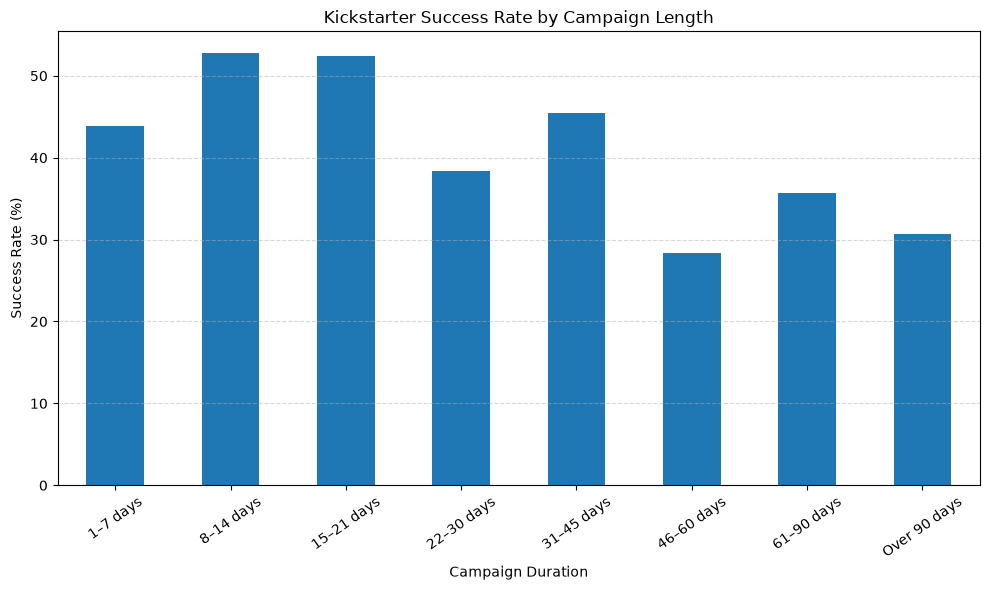

In [11]:
# Group campaign durations into ranges
bins = [0, 7, 14, 21, 30, 45, 60, 90, float("inf")]
labels = [
    "1–7 days", "8–14 days", "15–21 days",
    "22–30 days", "31–45 days", "46–60 days",
    "61–90 days", "Over 90 days"
]

analysis_df["duration_group"] = pd.cut(
    analysis_df["campaign_days"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

# Calculate success rate for each duration group
success_rates = (
    analysis_df.groupby("duration_group", observed=False)["state"]
    .apply(lambda states: (states == "successful").mean() * 100)
    .dropna()
)

ax = success_rates.plot(kind="bar", figsize=(10, 6))

ax.set_title("Kickstarter Success Rate by Campaign Length")
ax.set_xlabel("Campaign Duration")
ax.set_ylabel("Success Rate (%)")
ax.tick_params(axis="x", rotation=35)
ax.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

The graph compares Kickstarter success rates across different campaign durations. Campaigns lasting 8–14 days and 15–21 days have the highest success rates, at approximately 53%. In comparison, campaigns lasting 46–60 days have the lowest success rate, at about 28%. The graph suggests that shorter campaigns may be associated with higher success rates in this dataset. However, this is an initial observation and does not prove that shorter campaigns cause projects to succeed. Other factors, such as funding goals, project categories, and audience interest, may also influence the results.

In [12]:
# Create a separate DataFrame for funding-goal analysis
goal_df = analysis_df.copy()

# Convert funding goal to numeric values
goal_df["goal"] = pd.to_numeric(goal_df["goal"], errors="coerce")

# Keep only valid, positive funding goals
goal_df = goal_df[
    goal_df["goal"].notna() & (goal_df["goal"] > 0)
].copy()

print("Projects available:", len(goal_df))
print("\nFunding goal summary:")
print(goal_df["goal"].describe())

Projects available: 281302

Funding goal summary:
count    2.813020e+05
mean     4.183306e+04
std      1.044424e+06
min      1.000000e-02
25%      2.000000e+03
50%      5.000000e+03
75%      1.500000e+04
max      1.000000e+08
Name: goal, dtype: float64


In [13]:
import numpy as np

# Create funding-goal ranges
bins = [0, 1000, 5000, 10000, 25000, 50000, 100000, float("inf")]
labels = [
    "$1–$1,000",
    "$1,001–$5,000",
    "$5,001–$10,000",
    "$10,001–$25,000",
    "$25,001–$50,000",
    "$50,001–$100,000",
    "Over $100,000"
]

goal_df["goal_range"] = pd.cut(
    goal_df["goal"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

# Calculate success rate for each funding-goal range
goal_success_rates = (
    goal_df.groupby("goal_range", observed=False)["state"]
    .apply(lambda states: (states == "successful").mean() * 100)
    .dropna()
)

print(goal_success_rates.round(2))

goal_range
$1–$1,000           52.84
$1,001–$5,000       46.54
$5,001–$10,000      38.93
$10,001–$25,000     33.41
$25,001–$50,000     24.70
$50,001–$100,000    16.74
Over $100,000        8.07
Name: state, dtype: float64


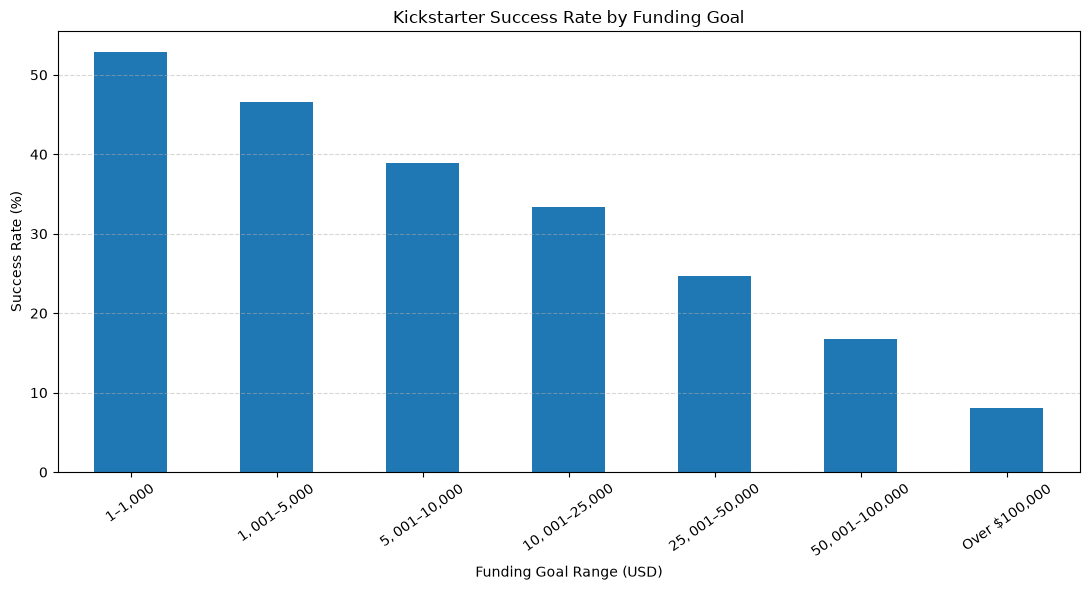

In [14]:
ax = goal_success_rates.plot(
    kind="bar",
    figsize=(11, 6)
)

ax.set_title("Kickstarter Success Rate by Funding Goal")
ax.set_xlabel("Funding Goal Range (USD)")
ax.set_ylabel("Success Rate (%)")
ax.tick_params(axis="x", rotation=35)
ax.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

The graph shows that Kickstarter success rates decrease as funding goals increase. Projects with goals between $1 and $1,000 have the highest success rate, at 52.84%, while projects with goals above $100,000 have the lowest rate, at 8.07%. This pattern suggests that projects with lower funding goals are more likely to succeed in this dataset. One possible explanation is that smaller goals may be easier for creators to reach. However, these results do not prove that lower goals directly cause success, because other factors, such as project category, campaign length, and audience interest, may also affect the outcome.

In [15]:
# Create a separate DataFrame for launch-timing analysis
launch_df = analysis_df.copy()

# Remove rows with missing launch dates
launch_df = launch_df.dropna(subset=["launched"]).copy()

# Extract launch month
launch_df["launch_month"] = launch_df["launched"].dt.month

# Map month numbers to names
month_names = {
    1: "January", 2: "February", 3: "March",
    4: "April", 5: "May", 6: "June",
    7: "July", 8: "August", 9: "September",
    10: "October", 11: "November", 12: "December"
}

launch_df["launch_month_name"] = launch_df["launch_month"].map(month_names)

print("Projects included:", len(launch_df))
print("\nLaunch month counts:")
print(launch_df["launch_month_name"].value_counts().reindex(month_names.values()))

Projects included: 281302

Launch month counts:
launch_month_name
January      20475
February     22662
March        25386
April        24676
May          24827
June         24928
July         28276
August       24536
September    23782
October      24898
November     21674
December     15182
Name: count, dtype: int64


In [16]:
monthly_success_rates = (
    launch_df.groupby("launch_month", sort=True)["state"]
    .apply(lambda states: (states == "successful").mean() * 100)
)

monthly_success_rates.index = [
    month_names[month] for month in monthly_success_rates.index
]

print("Success rate by launch month (%):")
print(monthly_success_rates.round(2))

Success rate by launch month (%):
January      38.38
February     41.92
March        42.51
April        42.32
May          41.48
June         40.63
July         36.00
August       37.54
September    40.52
October      41.80
November     40.91
December     37.94
Name: state, dtype: float64


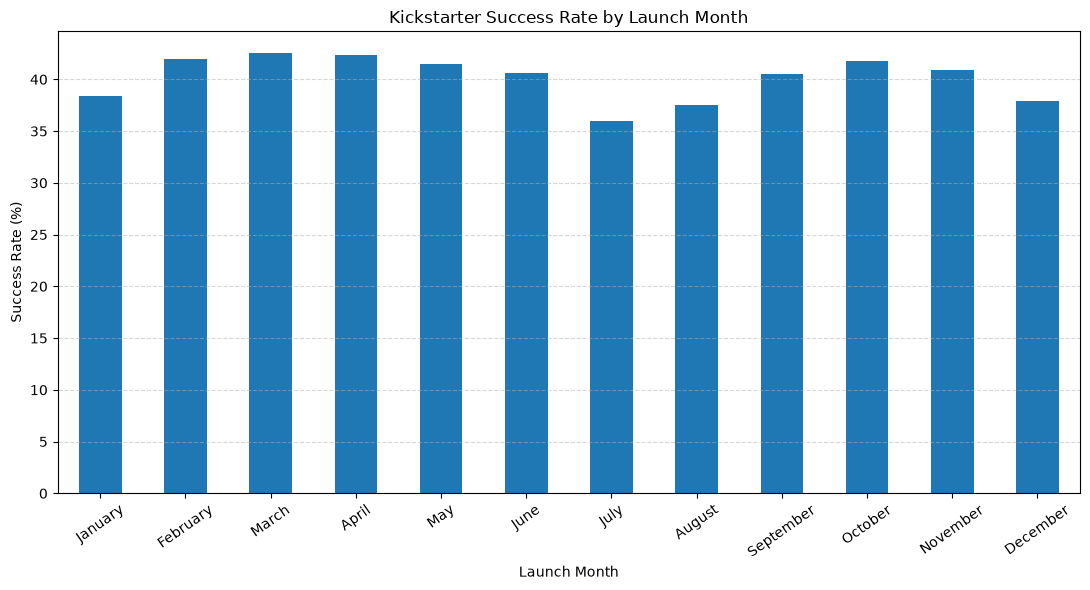

In [17]:
ax = monthly_success_rates.plot(
    kind="bar",
    figsize=(11, 6)
)

ax.set_title("Kickstarter Success Rate by Launch Month")
ax.set_xlabel("Launch Month")
ax.set_ylabel("Success Rate (%)")
ax.tick_params(axis="x", rotation=35)
ax.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

The graph compares Kickstarter success rates across the twelve launch months. March has the highest success rate at 42.51%, followed closely by April at 42.32%. July has the lowest success rate at 36.00%. The difference suggests that launch timing may be associated with project success, although the variation across months is relatively small. These results do not establish that launching in a particular month causes a project to succeed. Other factors, including funding goals, campaign duration, project category, and audience interest, may also influence success.